In [ ]:

# Cell 1: Upload the Hospital ER Dataset

from google.colab import files

uploaded = files.upload()


Saving Hospital ER_Data.csv to Hospital ER_Data.csv


### Inspect Column Names and Structure
Let's load the first few lines of the CSV file to see its column names and structure.

In [ ]:
import pandas as pd

# Quick load to inspect schema and first few rows
df_temp = pd.read_csv('Hospital ER_Data.csv', nrows=5)
display(df_temp)
print(df_temp.info())

,Patient Id,Patient Admission Date,Patient First Inital,Patient Last Name,Patient Gender,Patient Age,Patient Race,Department Referral,Patient Admission Flag,Patient Satisfaction Score,Patient Waittime,Patients CM
0,145-39-5406,20-03-2024 08:47,H,Glasspool,M,69,White,NaN,False,10.0,39,0
1,316-34-3057,15-06-2024 11:29,X,Methuen,M,4,Native American/Alaska Native,NaN,True,NaN,27,0
2,897-46-3852,20-06-2024 09:13,P,Schubuser,F,56,African American,General Practice,True,9.0,55,0
3,358-31-9711,04-02-2024 22:34,U,Titcombe,F,24,Native American/Alaska Native,General Practice,True,8.0,31,0
4,289-26-0537,04-09-2024 17:48,Y,Gionettitti,M,5,African American,Orthopedics,False,NaN,10,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Patient Id                  5 non-null      object 
 1   Patient Admission Date      5 non-null      object 
 2   Patient First Inital        5 non-null      object 
 3   Patient Last Name           5 non-null      object 
 4   Patient Gender              5 non-null      object 
 5   Patient Age                 5 non-null      int64  
 6   Patient Race                5 non-null      object 
 7   Department Referral         3 non-null      object 
 8   Patient Admission Flag      5 non-null      bool   
 9   Patient Satisfaction Score  3 non-null      float64
 10  Patient Waittime            5 non-null      int64  
 11  Patients CM                 5 non-null      int64  
dtypes: bool(1), float64(1), int64(3), object(7)
memory usage: 577.0+ bytes
None


# T12 — Explore Available Frameworks for Customer Analytics

## Part A — Theoretical Content

### 1. Customer Analytics in Healthcare & Importance
Customer analytics in healthcare focuses on capturing, analyzing, and interpreting patient-related data to improve clinical outcomes, service delivery, and hospital operations. By understanding patient demographics, preferences, satisfaction levels, and wait times, healthcare organizations can optimize resource allocation, enhance the overall patient experience, reduce clinical bottlenecks, and design more effective, patient-centric healthcare pathways.

### 2. The Four Health Analytics Disciplines
*   **Information Management:** The foundational layer focused on data collection, integration, governance, and maintaining data quality across various clinical systems (e.g., Electronic Health Records).
*   **Statistics and Analytics:** The mathematical and analytical layer involving descriptive, predictive, and prescriptive methodologies to uncover patterns, trends, and clinical correlations.
*   **Information Delivery:** The reporting and communication layer, transforming raw data and analytical insights into accessible dashboards, alerts, and structured reports for clinical or administrative decision-makers.
*   **High-Performance Computing:** The infrastructure layer providing the raw processing power, scalability, and technical capacity required to handle massive, complex healthcare datasets (Big Data) in real-time or near-real-time environments.

### 3. Customer Analytics Approaches
*   **Patient Segmentation:** Grouping patients into distinct cohorts based on attributes such as age, gender, clinical needs, or risk profiles to deliver tailored care interventions.
*   **Descriptive Analytics:** Examining historical patient data (e.g., volume, admission rates) to summarize what has happened over a given timeframe.
*   **Satisfaction Analysis:** Assessing qualitative feedback, such as Patient Satisfaction Scores, to evaluate the perceived quality of service and care.
*   **Behavioural Analytics:** Examining how patients interact with healthcare services, such as patterns in clinic visits, emergency room utilization, or adherence to treatments.

### 4. HIPAA and Regulatory Context
The Health Insurance Portability and Accountability Act (HIPAA) is a United States federal law enacted to protect sensitive patient health information (Protected Health Information, or PHI) from being disclosed without the patient's consent or knowledge. **Important Note:** HIPAA is a US national regulatory framework. While its core principles of data privacy and security serve as gold-standard reference points globally, HIPAA should not automatically be treated as legally applicable to healthcare organizations operating in other jurisdictions, such as India, which are subject to their own local digital privacy regulations (e.g., the Digital Personal Data Protection Act, DPDP, in India).

## Part B — Python Implementation

### Cell 1 — Import Libraries

In [ ]:
# Cell 1: Import necessary libraries for data manipulation and visualization
import pandas as pd
import matplotlib.pyplot as plt


### Cell 2 — Load Dataset

In [ ]:
# Cell 2: Load the Hospital ER dataset and display the first five rows (non-identifying columns only)
df = pd.read_csv('Hospital ER_Data.csv')

# Identify non-identifying columns to safely display
non_identifying_cols = [
    'Patient Gender', 'Patient Age', 'Patient Race',
    'Department Referral', 'Patient Admission Flag',
    'Patient Satisfaction Score', 'Patient Waittime'
]
display(df[non_identifying_cols].head(5))

,Patient Gender,Patient Age,Patient Race,Department Referral,Patient Admission Flag,Patient Satisfaction Score,Patient Waittime
0,M,69,White,NaN,False,10.0,39
1,M,4,Native American/Alaska Native,NaN,True,NaN,27
2,F,56,African American,General Practice,True,9.0,55
3,F,24,Native American/Alaska Native,General Practice,True,8.0,31
4,M,5,African American,Orthopedics,False,NaN,10


### Cell 3 — Dataset Overview

In [ ]:
# Cell 3: Display basic structural overview of the dataset while omitting personal details
print("=== Dataset Structural Overview ===")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

print("\n=== Column Names and Data Types ===")
print(df.dtypes)

print("\n=== Missing Values Per Column ===")
print(df.isnull().sum())

print("\n=== Duplicate Row Count ===")
print(f"Total duplicates: {df.duplicated().sum()}")

print("\n=== Summary Statistics for Relevant Numerical Columns ===")
# Display summary statistics only for non-identifying, relevant numerical fields
numerical_cols = ['Patient Age', 'Patient Waittime', 'Patient Satisfaction Score']
print(df[numerical_cols].describe())

=== Dataset Structural Overview ===
Number of rows: 9216
Number of columns: 12

=== Column Names and Data Types ===
Patient Id                     object
Patient Admission Date         object
Patient First Inital           object
Patient Last Name              object
Patient Gender                 object
Patient Age                     int64
Patient Race                   object
Department Referral            object
Patient Admission Flag           bool
Patient Satisfaction Score    float64
Patient Waittime                int64
Patients CM                     int64
dtype: object

=== Missing Values Per Column ===
Patient Id                       0
Patient Admission Date           0
Patient First Inital             0
Patient Last Name                0
Patient Gender                   0
Patient Age                      0
Patient Race                     0
Department Referral           5400
Patient Admission Flag           0
Patient Satisfaction Score    6699
Patient Waittime             

### Cell 4 — Data Preparation

In [ ]:
# Cell 4: Prepare and clean data safely without fabricating details or removing data unnecessarily

# Ensure proper datatypes
df['Patient Age'] = pd.to_numeric(df['Patient Age'], errors='coerce')
df['Patient Waittime'] = pd.to_numeric(df['Patient Waittime'], errors='coerce')
df['Patient Satisfaction Score'] = pd.to_numeric(df['Patient Satisfaction Score'], errors='coerce')

# Exclude personal identifiers from analytic views
analytic_cols = [
    'Patient Gender', 'Patient Age', 'Patient Race',
    'Department Referral', 'Patient Admission Flag',
    'Patient Satisfaction Score', 'Patient Waittime'
]
df_analytic = df[analytic_cols].copy()

# Assess satisfaction scores separately to maintain data integrity
satisfaction_df = df_analytic.dropna(subset=['Patient Satisfaction Score'])
satisfaction_sample_size = len(satisfaction_df)

print("=== Data Preparation Summary ===")
print(f"Total analytical records: {len(df_analytic)}")
print(f"Sample size with valid satisfaction scores: {satisfaction_sample_size}")

=== Data Preparation Summary ===
Total analytical records: 9216
Sample size with valid satisfaction scores: 2517


### Cell 5 — Patient Segmentation

In [ ]:
# Cell 5: Create patient age segments and compare them using descriptive statistics

# Check age range
min_age = int(df_analytic['Patient Age'].min())
max_age = int(df_analytic['Patient Age'].max())
print(f"Patient Age Range: {min_age} to {max_age} years\n")

# Define logical age groups
bins = [0, 12, 18, 35, 50, 65, 100]
labels = ['Children (0-12)', 'Adolescents (13-18)', 'Young Adults (19-35)', 'Middle-Aged (36-50)', 'Older Adults (51-65)', 'Seniors (66+)']

df_analytic['Age Group'] = pd.cut(df_analytic['Patient Age'], bins=bins, labels=labels, right=True)

# Construct summary table
age_segmentation = df_analytic.groupby('Age Group', observed=False).agg(
    Patient_Count=('Patient Age', 'count'),
    Average_Age=('Patient Age', 'mean'),
    Average_Waittime=('Patient Waittime', 'mean')
).reset_index()

display(age_segmentation)

Patient Age Range: 1 to 79 years



,Age Group,Patient_Count,Average_Age,Average_Waittime
0,Children (0-12),1413,6.566879,35.302902
1,Adolescents (13-18),697,15.639885,35.350072
2,Young Adults (19-35),1985,26.974811,35.499748
3,Middle-Aged (36-50),1776,42.840090,35.351914
4,Older Adults (51-65),1728,58.008681,34.864583
5,Seniors (66+),1617,72.515152,35.210266


### Cell 6 — Healthcare Service Usage Analysis

In [ ]:
# Cell 6: Analyze Department Referrals and Admission flags while handling missing values transparently

print("=== Department Referral Distribution (Excluding Missing Values) ===")
dept_distribution = df_analytic['Department Referral'].value_counts(dropna=True)
display(dept_distribution.to_frame('Patient Count'))

missing_referrals = df_analytic['Department Referral'].isnull().sum()
print(f"\nNumber of patients with unrecorded/missing department referral: {missing_referrals}")

print("\n=== Patient Admission Flag Distribution ===")
admission_distribution = df_analytic['Patient Admission Flag'].value_counts()
display(admission_distribution.to_frame('Patient Count'))

=== Department Referral Distribution (Excluding Missing Values) ===


,Patient Count
Department Referral,
General Practice,1840
Orthopedics,995
Physiotherapy,276
Cardiology,248
Neurology,193
Gastroenterology,178
Renal,86



Number of patients with unrecorded/missing department referral: 5400

=== Patient Admission Flag Distribution ===


,Patient Count
Patient Admission Flag,
True,4612
False,4604


### Cell 7 — Patient Satisfaction Analysis

In [ ]:
# Cell 7: Perform patient satisfaction analysis across age groups

# Keep only valid satisfaction records
sat_data = df_analytic.dropna(subset=['Patient Satisfaction Score'])

overall_avg_sat = sat_data['Patient Satisfaction Score'].mean()
overall_median_sat = sat_data['Patient Satisfaction Score'].median()

print(f"=== Overall Satisfaction Analysis ===")
print(f"Valid observations used: {len(sat_data)}")
print(f"Overall Average Score: {overall_avg_sat:.2f} / 10")
print(f"Overall Median Score: {overall_median_sat:.1f} / 10\n")

print("=== Average Satisfaction by Age Group ===")
sat_by_age = sat_data.groupby('Age Group', observed=False).agg(
    Avg_Satisfaction=('Patient Satisfaction Score', 'mean'),
    Response_Count=('Patient Satisfaction Score', 'count')
).reset_index()

display(sat_by_age)

=== Overall Satisfaction Analysis ===
Valid observations used: 2517
Overall Average Score: 4.99 / 10
Overall Median Score: 5.0 / 10

=== Average Satisfaction by Age Group ===


,Age Group,Avg_Satisfaction,Response_Count
0,Children (0-12),5.089744,390
1,Adolescents (13-18),4.691429,175
2,Young Adults (19-35),5.012411,564
3,Middle-Aged (36-50),5.190776,477
4,Older Adults (51-65),5.058065,465
5,Seniors (66+),4.717489,446


### Cell 8 — Waiting-Time Analysis

In [ ]:
# Cell 8: Analyze patient waiting times across department referrals

overall_mean_wait = df_analytic['Patient Waittime'].mean()
overall_median_wait = df_analytic['Patient Waittime'].median()
missing_wait_count = df_analytic['Patient Waittime'].isnull().sum()

print("=== Overall Wait Time Metrics ===")
print(f"Overall Average Wait Time: {overall_mean_wait:.2f} minutes")
print(f"Overall Median Wait Time: {overall_median_wait:.2f} minutes")
print(f"Missing Wait Time values: {missing_wait_count}\n")

print("=== Average and Median Wait Time by Department Referral ===")
wait_by_dept = df_analytic.groupby('Department Referral', observed=False).agg(
    Avg_Wait_Time=('Patient Waittime', 'mean'),
    Median_Wait_Time=('Patient Waittime', 'median'),
    Patient_Count=('Patient Waittime', 'count')
).reset_index()

display(wait_by_dept)

=== Overall Wait Time Metrics ===
Overall Average Wait Time: 35.26 minutes
Overall Median Wait Time: 35.00 minutes
Missing Wait Time values: 0

=== Average and Median Wait Time by Department Referral ===


,Department Referral,Avg_Wait_Time,Median_Wait_Time,Patient_Count
0,Cardiology,35.354839,35.0,248
1,Gastroenterology,35.831461,36.0,178
2,General Practice,34.912500,35.0,1840
3,Neurology,36.803109,38.0,193
4,Orthopedics,34.982915,34.0,995
5,Physiotherapy,36.565217,38.5,276
6,Renal,34.697674,35.0,86


### Cell 9 — Data Visualization

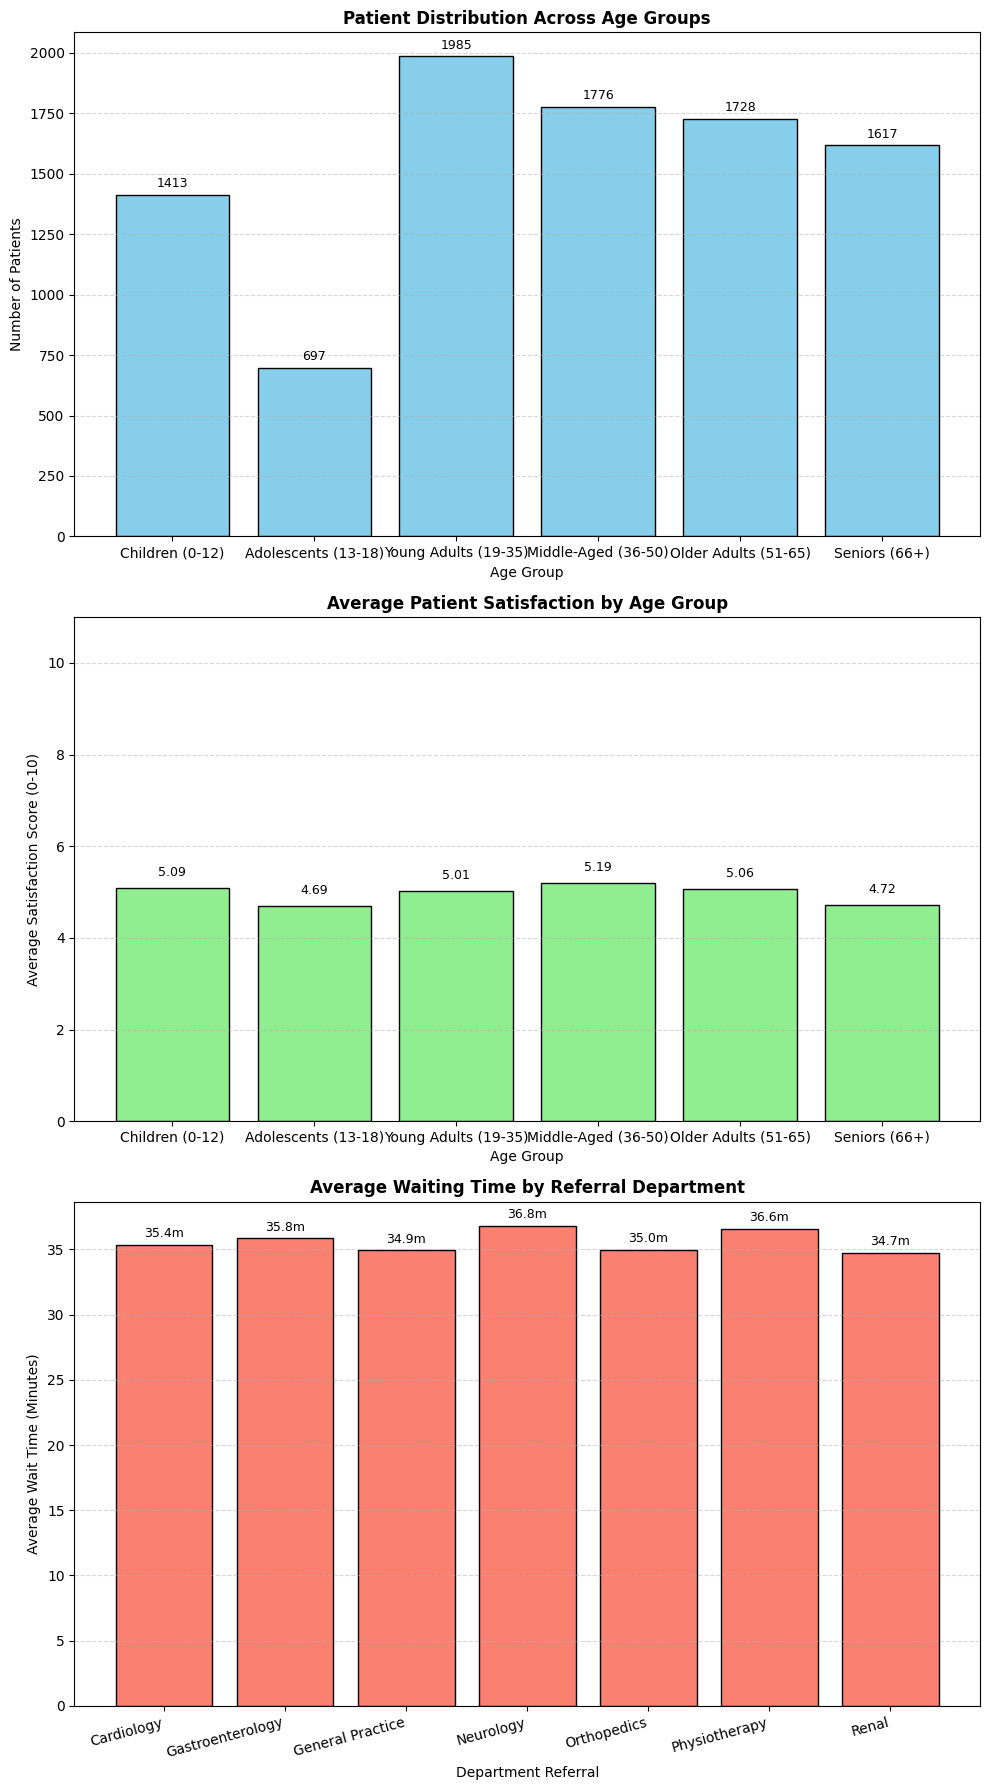

In [ ]:
# Cell 9: Generate clean visualizations for findings reporting

# Setup plot structure
fig, axes = plt.subplots(3, 1, figsize=(10, 18))

# Chart 1: Patient distribution across age groups
age_group_counts = df_analytic['Age Group'].value_counts().sort_index()
axes[0].bar(age_group_counts.index, age_group_counts.values, color='skyblue', edgecolor='black')
axes[0].set_title('Patient Distribution Across Age Groups', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Age Group', fontsize=10)
axes[0].set_ylabel('Number of Patients', fontsize=10)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)
for i, val in enumerate(age_group_counts.values):
    axes[0].text(i, val + (max(age_group_counts.values)*0.01), str(val), ha='center', va='bottom', fontsize=9)

# Chart 2: Average patient satisfaction by age group (only valid data)
sat_by_age_clean = sat_by_age.dropna(subset=['Avg_Satisfaction'])
axes[1].bar(sat_by_age_clean['Age Group'].astype(str), sat_by_age_clean['Avg_Satisfaction'], color='lightgreen', edgecolor='black')
axes[1].set_title('Average Patient Satisfaction by Age Group', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Age Group', fontsize=10)
axes[1].set_ylabel('Average Satisfaction Score (0-10)', fontsize=10)
axes[1].set_ylim(0, 11)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
for i, val in enumerate(sat_by_age_clean['Avg_Satisfaction']):
    axes[1].text(i, val + 0.2, f"{val:.2f}", ha='center', va='bottom', fontsize=9)

# Chart 3: Average waiting time by department referral
wait_by_dept_clean = wait_by_dept.dropna(subset=['Avg_Wait_Time'])
axes[2].bar(wait_by_dept_clean['Department Referral'], wait_by_dept_clean['Avg_Wait_Time'], color='salmon', edgecolor='black')
axes[2].set_title('Average Waiting Time by Referral Department', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Department Referral', fontsize=10)
axes[2].set_ylabel('Average Wait Time (Minutes)', fontsize=10)
axes[2].grid(axis='y', linestyle='--', alpha=0.5)
plt.setp(axes[2].get_xticklabels(), rotation=15, ha='right')
for i, val in enumerate(wait_by_dept_clean['Avg_Wait_Time']):
    axes[2].text(i, val + (max(wait_by_dept_clean['Avg_Wait_Time'])*0.01), f"{val:.1f}m", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

### Cell 10 — Findings and Conclusion

In [ ]:
# Cell 10: Print dynamic findings based on computed results and present the structural conclusion

# Extract highest/most common elements dynamically
max_age_group = age_group_counts.idxmax()
max_age_val = age_group_counts.max()

most_common_dept = dept_distribution.idxmax()
most_common_dept_val = dept_distribution.max()

overall_mean_sat = sat_data['Patient Satisfaction Score'].mean()

highest_wait_dept = wait_by_dept_clean.loc[wait_by_dept_clean['Avg_Wait_Time'].idxmax(), 'Department Referral']
highest_wait_val = wait_by_dept_clean['Avg_Wait_Time'].max()

print("=== Summary of Empirical Findings ===")
print(f"1. Largest Patient Cohort: {max_age_group} with {max_age_val} patients.")
print(f"2. Most Common Department Referral: {most_common_dept} ({most_common_dept_val} cases).")
print(f"3. Average Patient Satisfaction: {overall_mean_sat:.2f} out of 10. Note: This score is based on 2,517 valid responses out of 9,216 records, with the remaining records missing satisfaction scores.")
print(f"4. Highest Waiting Time Department: {highest_wait_dept} (Average wait: {highest_wait_val:.2f} minutes).\n")

print("=== Conclusion ===")
print("This customer analytics exercise shows how descriptive profiling helps hospitals pinpoint operational strengths and bottlenecks.\n"
      "- Patient segmentation isolates specific demographics (e.g. vulnerable age cohorts) to adjust staffing needs.\n"
      "- Descriptive analytics and wait-time comparisons locate specific departments needing process improvements.\n"
      "- Satisfaction scores highlight patient perceptions, aligning institutional metrics with patient-centered goals.\n\n"
      "Disclaimer: These results present historical associations and descriptive trends. They must not be interpreted as\n"
      "establishing direct causal linkages without controlled, clinical-operational study designs.")

=== Summary of Empirical Findings ===
1. Largest Patient Cohort: Young Adults (19-35) with 1985 patients.
2. Most Common Department Referral: General Practice (1840 cases).
3. Average Patient Satisfaction: 4.99 out of 10. Note: This score is based on 2,517 valid responses out of 9,216 records, with the remaining records missing satisfaction scores.
4. Highest Waiting Time Department: Neurology (Average wait: 36.80 minutes).

=== Conclusion ===
This customer analytics exercise shows how descriptive profiling helps hospitals pinpoint operational strengths and bottlenecks.
- Patient segmentation isolates specific demographics (e.g. vulnerable age cohorts) to adjust staffing needs.
- Descriptive analytics and wait-time comparisons locate specific departments needing process improvements.
- Satisfaction scores highlight patient perceptions, aligning institutional metrics with patient-centered goals.

Disclaimer: These results present historical associations and descriptive trends. They must